TSNE

In [108]:
import numpy as np
import matplotlib.pyplot as plt

In [109]:
import torch
from train_mnist import get_model 
model = get_model()
model.load_state_dict(torch.load("mnist_cnn.pt", map_location="cpu"))
model

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Flatten(start_dim=1, end_dim=-1)
  (15): Linear(in_features=3136, out_features=256, bias=True)
  (16): ReLU()
  (17):

In [110]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

data = datasets.MNIST("data", download=True, transform=tf)
class WithIdx(torch.utils.data.Dataset):
    def __init__(self, ds): self.ds = ds
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        x, y = self.ds[i]
        return x, y, i
loader = DataLoader(WithIdx(data), batch_size=128, shuffle=True)


model[16]._forward_hooks.clear()

emb = []
def hook(m, inp, out):
	global emb
	emb.append(out.detach())
model[16].register_forward_hook(hook)

ixs = []

model.eval()
for x, y, i in loader:
	with torch.no_grad():
		model(x)
		ixs.extend(i)
	break

emb = torch.cat(emb)
ixs = torch.tensor(ixs)
emb.shape, ixs.shape

(torch.Size([128, 256]), torch.Size([128]))

Hinton & Roweis, 2002 method

$$ p_{j|i} = \frac{exp(-\|x_i - x_j \|^2 / 2 \sigma_i^2)}{\sum_{i\neq k} exp(-\|x_i - x_k \|^2 / 2 \sigma_i^2)} $$

A) with $x_i$ as the center of gaussian of $\sigma_i$. and find $x_j$ on that curve. normalize to $\sum p_{j|i} = 1$

B) with logits $-\|x_i - x_j \|^2 / 2 \sigma_i^2$, we softmax over. does two things: makes everything positive and reveals linear differences as exponential differences. we then normalize so they are probabilities that sum to one.

Find $\sigma$ via perplexity (dial you use to change $\sigma$ for each set):
$$\text{Perp}(P_i) = 2^{H(P_i)}, \quad H(P_i) = -\sum_j p_{j|i} \log_2 p_{j|i}$$


In [111]:
# adjust spread
perp = 30 # default but trail and error adjust

B, C = emb.shape

# binary search
H_target = np.log(perp)
lo, hi = torch.zeros(B), torch.full((B,), float('inf'))
var = torch.ones(B)*100
while True:
	# emb: (B, C)
	# pair wise sub (B, B, C) ==> x_i - x_j
	logits = -torch.sum((emb[None,:,:]-emb[:,None,:])**2, -1) / (2*var[:,None])
	# to match i != j condition above
	logits.fill_diagonal_(float('-inf'))
 	# horizontall sums to one
	p_ji = torch.softmax(logits, dim=1)
	# entorpy
	H_i = -torch.xlogy(p_ji, p_ji).sum(1) / np.log(2)
	
	if torch.all(torch.abs(H_i - H_target) < 1e-5):
		break

	mask = H_i > H_target

	hi[mask] = var[mask]
	var[mask] = (lo[mask] + hi[mask])/2
	lo[~mask] = var[~mask]

	unb = ~mask & torch.isinf(hi)
	bnd = ~mask & ~torch.isinf(hi)
	var[unb] = var[unb] * 2
	var[bnd] = (lo[bnd] + hi[bnd]) / 2

var.shape

torch.Size([128])

symmetrize
$$p_{ij} = \frac{p_{j|i} + p_{i|j}}{2N}$$

In [112]:

logits = -torch.sum((emb[None,:,:]-emb[:,None,:])**2, -1) / (2*var[:,None])
logits.fill_diagonal_(float('-inf'))
p_ij = torch.softmax(logits, dim=1)

p = (p_ij + p_ij.T) / (2 * B)
p.shape

torch.Size([128, 128])

Crowding problem in lower dims. Sharper drop off $~ 1/r^2$ so further points are easier to move.

So let's instead use student-t

$$q_{ij} = \frac{(1 + \|y_i - y_j\|^2)^{-1}}{\sum_{k \neq l} (1 + \|y_k - y_l\|^2)^{-1}}$$

In [113]:
y = torch.randn(B, 2).requires_grad_()
logits = -torch.log(1 + torch.sum(y[None, :, :] - y[:, None, :], dim=-1)**2)
logits.fill_diagonal_(float("-inf"))
q = torch.softmax(logits.flatten(), dim=0).view(B, B)
q.shape

torch.Size([128, 128])

KL(P || Q). Cost distance function between probability dist P, Q

$$ KL(P\|Q) = H(P, Q) - H(P)$$

Ideally differnce between Xentropyloss and original loss is zero.

$$  = - \sum(p \log q) - \left( -\sum p \log p \right) = p \sum \log p/q $$

In [114]:
H_p = - torch.sum(torch.xlogy(p, p))
H_pq = - torch.sum(torch.xlogy(p, q))
loss = H_pq - H_p
loss

tensor(2.7340, grad_fn=<SubBackward0>)

Derivative on lower embeddings:

$$\frac{\partial C}{\partial y_i} = 4 \sum_j (p_{ij} - q_{ij})(y_i - y_j)(1 + \|y_i - y_j\|^2)^{-1}$$

But I'll just let autograd handle this. Forward and backward passes let's **torchify...**

In [115]:
# constant, everything related to p is held constant
H_p = - torch.sum(torch.xlogy(p, p))

# embedding paremeter
y = torch.randn(B, 2).requires_grad_()
opt = torch.optim.Adam([y], lr=0.5)

lossi = []

for _ in range(1000):
	# FIND new Q
	logits = -torch.log1p(torch.sum((y[None, :, :] - y[:, None, :])**2, dim=-1))
	logits.fill_diagonal_(float("-inf"))
	q = torch.softmax(logits.flatten(), dim=0).view(B, B)

	# LOSS
	off = ~torch.eye(B, dtype=torch.bool) # turn off the diagonals, causes nan
	H_pq = - torch.sum(torch.xlogy(p[off], q[off]))
	loss = H_pq - H_p

	lossi.append(loss.item())

	opt.zero_grad()
	loss.backward()
	opt.step()
print(loss.item())

0.1562199592590332


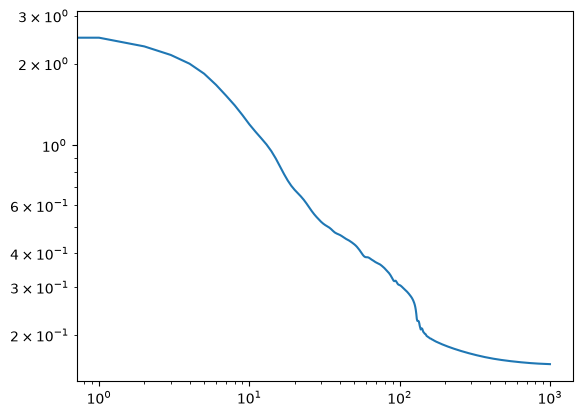

In [116]:
plt.loglog(lossi)

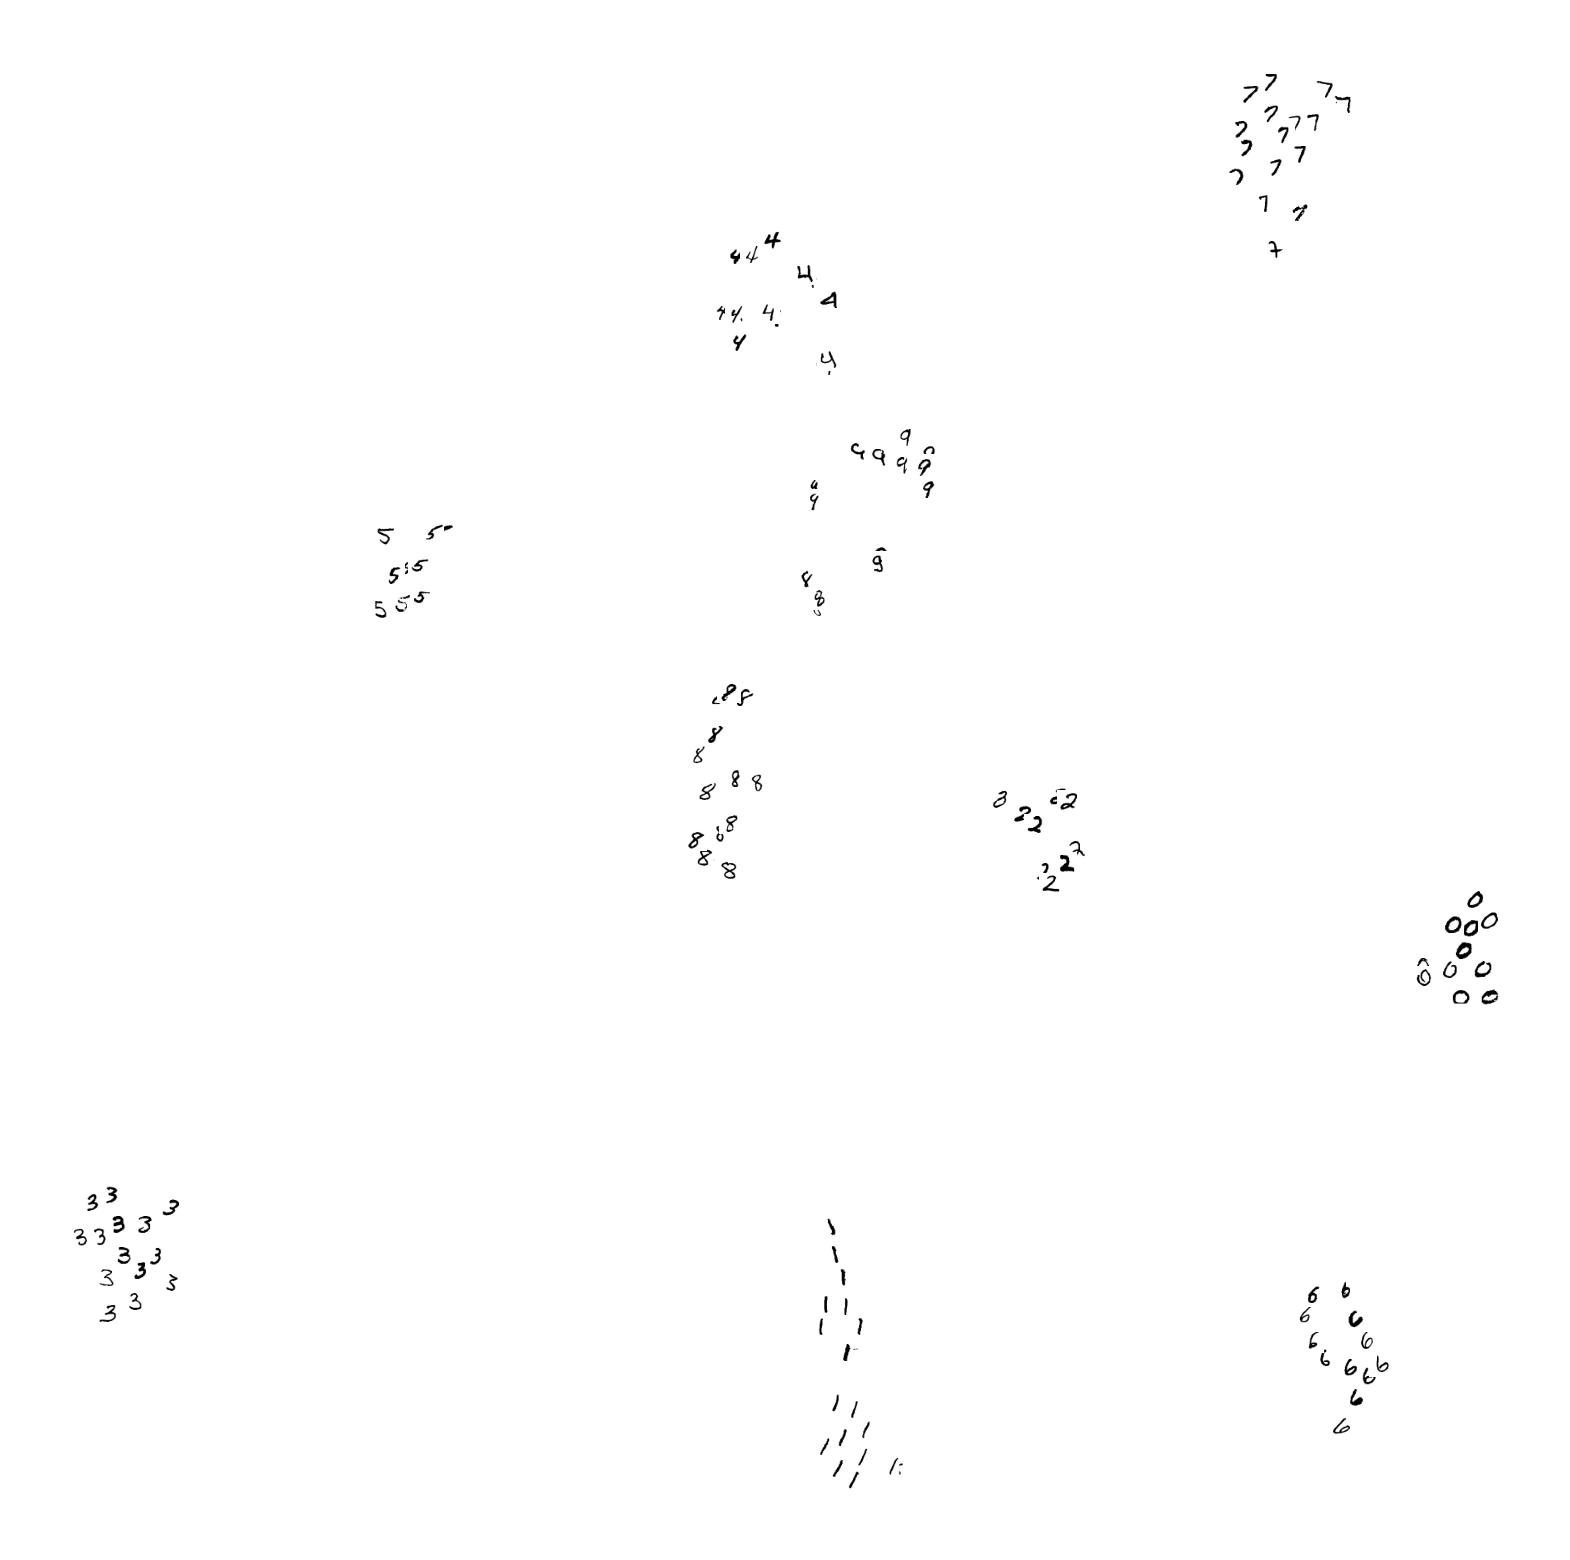

In [117]:
# CLAUDE

import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np

raw = datasets.MNIST("data", train=True, download=True)

Y = y.detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(20, 20))
ax.scatter(Y[:, 0], Y[:, 1], s=0)          # sets the axis limits

for (px, py), j in zip(Y, ixs):
    img = np.array(raw[j][0])              # PIL to array
    ab = AnnotationBbox(OffsetImage(img, cmap="gray_r", zoom=0.6),
                        (px, py), frameon=False)
    ax.add_artist(ab)

ax.axis("off")
plt.show()